# ED Nurse Staffing Optimization Engine
## Multi-Objective Optimization Analysis

**Student Name:** Michael Ho

**Target Company/Industry:** Health New Zealand | Te Whatu Ora (Health NZ)

**Problem:** Choose how many core and float nurses to roster on each ED shift so Health NZ spends as little of its weekly nursing budget as possible while getting as many patients as possible out of the ED within 6 hours.

**Objectives:** Maximize weekly budget remaining (NZD) vs. Maximize % of patients leaving the ED within 6 hours

---

## Project Overview

Health NZ have a publicly available goal to discharge 95% of ED patients within 6 hours. In the March 2026 quarter this was only achieved by 74.4%. There is also a lack of Registered Nurses in hospitals, with approximately 2000 less than required. Having more nurses on shift will increase patient flow, however there is a cost associated. Therefore there is a trade-off between how much money can be spent on nurses in the ED and the 6 hour discharge target. This analysis looks at the Auckland ED scenario and considers 120 different weekly scenarios. The variables are the number of core nurses (18-29 permanent RNs on roster) and floats (0-9 pool/agency nurses that are moved to the busiest area at the beginning of each shift). The weekly cost is converted into a remaining budget value based on a maximum of $380,000 being spent on nurses in the ED weekly. Both objectives are maximised.

# Section 1: Data Acquisition

The staff and patient data is private for Real Health NZ, therefore synthetic data was created using a LLM. The prompt used can be found in data/data_generation_prompt.txt. Data has been created to match real data, including the national 6hr result (74.4%) in March 2026 quarter and nurses pay scales (with penalties and agency premiums) from Health NZ.

In [1]:
import pandas as pd

# Load the data
df = pd.read_csv('data/ed_staffing_data.csv')

# Display first rows
print("Data loaded successfully!")
print(f"Shape: {df.shape}")
print("\nFirst 5 rows:")
print(df.head())

Data loaded successfully!
Shape: (120, 4)

First 5 rows:
   core_nurses_per_shift  float_nurses_per_shift  budget_remaining_nzd  \
0                     18                       0                197911   
1                     18                       1                181603   
2                     18                       2                166817   
3                     18                       3                149094   
4                     18                       4                134922   

   pct_within_6hrs  
0             55.1  
1             61.9  
2             65.5  
3             69.7  
4             72.3  


# Section 2: Data Exploration

In [2]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Basic statistics
print("\nBasic statistics:")
print(df.describe())

Missing values:
core_nurses_per_shift     0
float_nurses_per_shift    0
budget_remaining_nzd      0
pct_within_6hrs           0
dtype: int64

Data types:
core_nurses_per_shift       int64
float_nurses_per_shift      int64
budget_remaining_nzd        int64
pct_within_6hrs           float64
dtype: object

Basic statistics:
       core_nurses_per_shift  float_nurses_per_shift  budget_remaining_nzd  \
count             120.000000              120.000000            120.000000   
mean               23.500000                4.500000          72062.516667   
std                 3.466527                2.884324          56542.769372   
min                18.000000                0.000000         -52638.000000   
25%                20.750000                2.000000          33684.250000   
50%                23.500000                4.500000          72289.500000   
75%                26.250000                7.000000         112571.000000   
max                29.000000                9.000000 

In [3]:
# Check ranges of your decision variables
print(f"Decision Variable 1 range: {df['core_nurses_per_shift'].min()} to {df['core_nurses_per_shift'].max()}")
print(f"Decision Variable 2 range: {df['float_nurses_per_shift'].min()} to {df['float_nurses_per_shift'].max()}")

# Check if you have all combinations (if applicable)
print(f"\nTotal combinations: {len(df)}")

Decision Variable 1 range: 18 to 29
Decision Variable 2 range: 0 to 9

Total combinations: 120


In [4]:
print(f"Objective 1 (budget_remaining_nzd) range: {df['budget_remaining_nzd'].min()} to {df['budget_remaining_nzd'].max()}")
print(f"Objective 2 (pct_within_6hrs) range: {df['pct_within_6hrs'].min()} to {df['pct_within_6hrs'].max()}")

# Verify they create a tradeoff
correlation = df['budget_remaining_nzd'].corr(df['pct_within_6hrs'])
print(f"\nCorrelation between objectives: {correlation:.3f}")
print("(Negative correlation suggests a tradeoff)")

Objective 1 (budget_remaining_nzd) range: -52638 to 197911
Objective 2 (pct_within_6hrs) range: 55.1 to 91.9

Correlation between objectives: -0.941
(Negative correlation suggests a tradeoff)


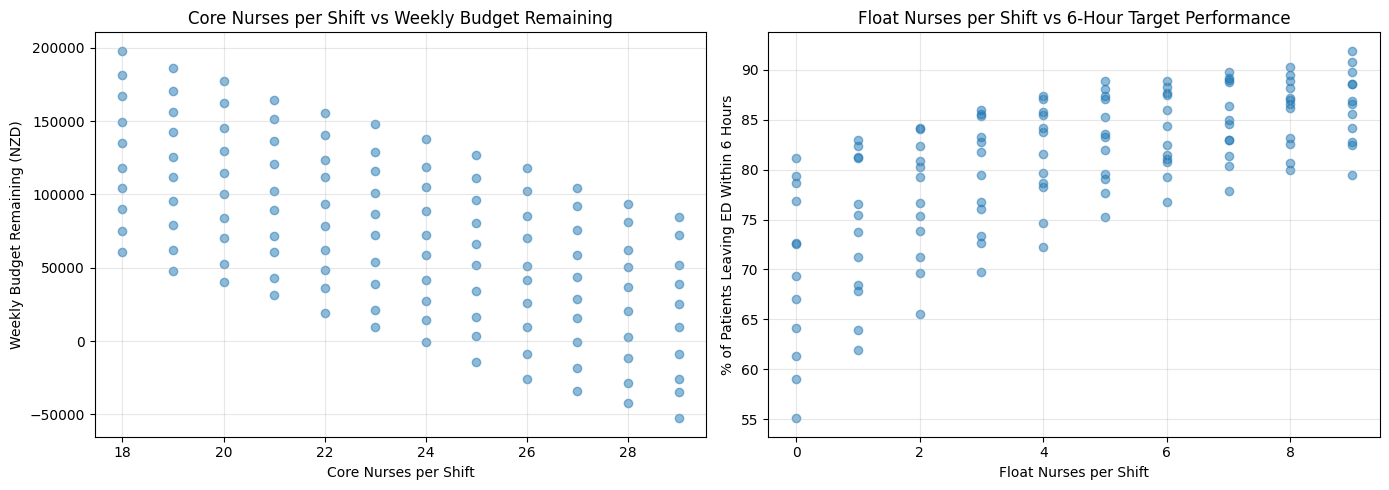

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: How decision variables affect objective 1
axes[0].scatter(df['core_nurses_per_shift'], df['budget_remaining_nzd'], alpha=0.5)
axes[0].set_xlabel('Core Nurses per Shift')
axes[0].set_ylabel('Weekly Budget Remaining (NZD)')
axes[0].set_title('Core Nurses per Shift vs Weekly Budget Remaining')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(df['float_nurses_per_shift'], df['pct_within_6hrs'], alpha=0.5)
axes[1].set_xlabel('Float Nurses per Shift')
axes[1].set_ylabel('% of Patients Leaving ED Within 6 Hours')
axes[1].set_title('Float Nurses per Shift vs 6-Hour Target Performance')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/data_exploration.png', dpi=300, bbox_inches='tight')
plt.show()

The data is complete, the variables have been correctly entered and there are no missing values. Every possible combination of core (18-29) and float (0-9) nurses per shift (120 combinations) have been included. The range of values make sense. The weekly budget left goes from approximately -$52,600 (14 rosters exceeding the $380,000 budget) to $197,900. The 6 hour rate ranges from 55.1% to 91.9%. None of the rosters reach the desired 95% due to the current lack of nurses. With a roster of 22 core and 2 float nurses it achieves a high of 75.4% which is similar to the national results of 74.4%. There is a strong negative correlation between the objectives (-0.941), showing that there is clearly a trade-off between the two. Adding more nurses will improve patient flow but will affect the budget. This matches what I expected in my proposal. Float nurses have had a higher increase in 6 hour rate per nurse added than core nurses as they are placed in the busiest areas.

# Section 3: Pareto Frontier Calculation

In [6]:
def is_pareto_optimal(idx, df, obj1_col, obj2_col):
    """
    Check if a given row represents a Pareto optimal solution.

    A point is Pareto optimal if no other point dominates it.
    Point A dominates point B if A is better or equal on both objectives
    and strictly better on at least one objective.

    Parameters:
    -----------
    idx : int
        Index of the row to check
    df : DataFrame
        The full dataset
    obj1_col : str
        Column name for objective 1
    obj2_col : str
        Column name for objective 2

    Returns:
    --------
    bool : True if Pareto optimal, False if dominated
    """
    current_obj1 = df.loc[idx, obj1_col]
    current_obj2 = df.loc[idx, obj2_col]

    # Check if any other point dominates this one
    for other_idx in df.index:
        if other_idx == idx:
            continue

        other_obj1 = df.loc[other_idx, obj1_col]
        other_obj2 = df.loc[other_idx, obj2_col]

        # Check if other point dominates current point
        # (other is >= on both objectives AND > on at least one)
        if (other_obj1 >= current_obj1 and
            other_obj2 >= current_obj2 and
            (other_obj1 > current_obj1 or other_obj2 > current_obj2)):
            return False  # This point is dominated

    return True  # No point dominates this one

In [7]:
# Define your objective column names
OBJECTIVE_1 = 'budget_remaining_nzd'
OBJECTIVE_2 = 'pct_within_6hrs'

print("Calculating Pareto frontier...")
print("This may take a moment for large datasets...")

# Apply Pareto check to all rows
df['is_pareto_optimal'] = df.index.map(
    lambda idx: is_pareto_optimal(idx, df, OBJECTIVE_1, OBJECTIVE_2)
)

# Separate into frontier and dominated points
pareto_df = df[df['is_pareto_optimal']].copy()
dominated_df = df[~df['is_pareto_optimal']].copy()

print("\n=== PARETO FRONTIER RESULTS ===")
print(f"Total solutions analyzed: {len(df)}")
print(f"Pareto optimal solutions: {len(pareto_df)}")
print(f"Dominated solutions: {len(dominated_df)}")
print(f"Efficiency rate: {100 * len(pareto_df) / len(df):.1f}% of solutions are on the frontier")

Calculating Pareto frontier...
This may take a moment for large datasets...

=== PARETO FRONTIER RESULTS ===
Total solutions analyzed: 120
Pareto optimal solutions: 40
Dominated solutions: 80
Efficiency rate: 33.3% of solutions are on the frontier


Only 40 of the 120 rosters (33.3%) are Pareto optimal. The remaining 80 are dominated by another roster which is cheaper (has more budget left over) but also meets the target of getting as many patients out within 6h. This is some what in line with what is expected as the float nurses have higher improvements in 6hr rate per nurse but also increased cost per hour. As there is significant tradeoff between core and float nurses (correlation = -0.941) there will never be a roster that is optimal across both criteria. Any roster on the frontier will always have an increase in 6h rate at the cost of budget. In the case of Health NZ, this means we can eliminate two thirds of the possible rosters and focus on choosing a roster on the frontier.

## Inefficient Solutions Analysis

In [8]:
if len(dominated_df) > 0:
    print("=== EXAMPLES OF DOMINATED (INEFFICIENT) SOLUTIONS ===\n")

    # Sample a few dominated points
    sample_size = min(3, len(dominated_df))
    sample_dominated = dominated_df.sample(sample_size, random_state=42)

    for idx, row in sample_dominated.iterrows():
        print(f"INEFFICIENT SOLUTION:")
        print(f"  Decision Variables: {row['core_nurses_per_shift']}, {row['float_nurses_per_shift']}")
        print(f"  Objectives: {OBJECTIVE_1}={row[OBJECTIVE_1]:.1f}, {OBJECTIVE_2}={row[OBJECTIVE_2]:.1f}")

        for p_idx, p_row in pareto_df.iterrows():
            if (p_row[OBJECTIVE_1] >= row[OBJECTIVE_1] and
                p_row[OBJECTIVE_2] >= row[OBJECTIVE_2] and
                (p_row[OBJECTIVE_1] > row[OBJECTIVE_1] or
                 p_row[OBJECTIVE_2] > row[OBJECTIVE_2])):

                print(f"\n  BETTER ALTERNATIVE (Pareto Optimal):")
                print(f"  Decision Variables: {p_row['core_nurses_per_shift']}, {p_row['float_nurses_per_shift']}")
                print(f"  Objectives: {OBJECTIVE_1}={p_row[OBJECTIVE_1]:.1f}, {OBJECTIVE_2}={p_row[OBJECTIVE_2]:.1f}")
                print(f"  Improvement: +{p_row[OBJECTIVE_1] - row[OBJECTIVE_1]:.1f} on {OBJECTIVE_1}, " +
                      f"+{p_row[OBJECTIVE_2] - row[OBJECTIVE_2]:.1f} on {OBJECTIVE_2}\n")
                print("-" * 60)
                break
else:
    print("Note: All solutions in your dataset are Pareto optimal.")
    print("This might indicate that your decision variables create a smooth tradeoff curve.")

=== EXAMPLES OF DOMINATED (INEFFICIENT) SOLUTIONS ===

INEFFICIENT SOLUTION:
  Decision Variables: 22, 5
  Objectives: budget_remaining_nzd=78717.0, pct_within_6hrs=82.0

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: 25, 3
  Objectives: budget_remaining_nzd=80744.0, pct_within_6hrs=83.3
  Improvement: +2027.0 on budget_remaining_nzd, +1.3 on pct_within_6hrs

------------------------------------------------------------
INEFFICIENT SOLUTION:
  Decision Variables: 18, 4
  Objectives: budget_remaining_nzd=134922.0, pct_within_6hrs=72.3

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: 19, 3
  Objectives: budget_remaining_nzd=142194.0, pct_within_6hrs=72.7
  Improvement: +7272.0 on budget_remaining_nzd, +0.4 on pct_within_6hrs

------------------------------------------------------------
INEFFICIENT SOLUTION:
  Decision Variables: 21, 6
  Objectives: budget_remaining_nzd=71872.0, pct_within_6hrs=81.1

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: 23

In [9]:
# Compare best dominated point to worst Pareto point
if len(dominated_df) > 0:
    best_dominated = dominated_df.loc[
        (dominated_df[OBJECTIVE_1] + dominated_df[OBJECTIVE_2]).idxmax()
    ]
    dominating_pareto = pareto_df[
        (pareto_df[OBJECTIVE_1] >= best_dominated[OBJECTIVE_1]) &
        (pareto_df[OBJECTIVE_2] >= best_dominated[OBJECTIVE_2])
    ].iloc[0]

    print("\n=== EFFICIENCY GAP ===")
    print("Even the BEST dominated solution is beaten by a Pareto solution:")
    print(f"\nBest Dominated: {best_dominated['core_nurses_per_shift']} core, {best_dominated['float_nurses_per_shift']} float, " +
          f"{OBJECTIVE_1}={best_dominated[OBJECTIVE_1]:.1f}, {OBJECTIVE_2}={best_dominated[OBJECTIVE_2]:.1f}")
    print(f"Pareto Alternative: {dominating_pareto['core_nurses_per_shift']} core, {dominating_pareto['float_nurses_per_shift']} float, " +
          f"{OBJECTIVE_1}={dominating_pareto[OBJECTIVE_1]:.1f}, {OBJECTIVE_2}={dominating_pareto[OBJECTIVE_2]:.1f}")


=== EFFICIENCY GAP ===
Even the BEST dominated solution is beaten by a Pareto solution:

Best Dominated: 20 core, 0 float, budget_remaining_nzd=177345.0, pct_within_6hrs=61.3
Pareto Alternative: 18 core, 1 float, budget_remaining_nzd=181603.0, pct_within_6hrs=61.9


# Section 4: Strategic Analysis

The budget left is expressed in terms of NZD (tens of thousands) and the six hour rate is expressed in %. Therefore if we just add or subtract them we will get large dollar amounts. To determine the balanced, equity and weighted strategies, both objectives are normalised so that they range between 0 and 100 on the Pareto frontier. The real values are presented in the tables below (NZD and %).

In [10]:
pareto_df['budget_score'] = 100 * (pareto_df[OBJECTIVE_1] - pareto_df[OBJECTIVE_1].min()) / (pareto_df[OBJECTIVE_1].max() - pareto_df[OBJECTIVE_1].min())
pareto_df['six_hour_score'] = 100 * (pareto_df[OBJECTIVE_2] - pareto_df[OBJECTIVE_2].min()) / (pareto_df[OBJECTIVE_2].max() - pareto_df[OBJECTIVE_2].min())

print("=== KEY STRATEGIC POINTS ON THE PARETO FRONTIER ===\n")

# Strategy 1: Balanced (Maximize total value)
pareto_df['total_objective'] = pareto_df['budget_score'] + pareto_df['six_hour_score']
balanced_idx = pareto_df['total_objective'].idxmax()

print("1. BALANCED STRATEGY (Maximize combined objectives)")
print(f"   Decision Variables: {pareto_df.loc[balanced_idx, 'core_nurses_per_shift']}, {pareto_df.loc[balanced_idx, 'float_nurses_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[balanced_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[balanced_idx, OBJECTIVE_2]:.1f}")
print(f"   Total: {pareto_df.loc[balanced_idx, 'total_objective']:.1f}\n")

# Strategy 2: Equity (Minimize gap between objectives)
pareto_df['objective_gap'] = abs(pareto_df['budget_score'] - pareto_df['six_hour_score'])
equity_idx = pareto_df['objective_gap'].idxmin()

print("2. EQUITY STRATEGY (Most equal outcomes)")
print(f"   Decision Variables: {pareto_df.loc[equity_idx, 'core_nurses_per_shift']}, {pareto_df.loc[equity_idx, 'float_nurses_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[equity_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[equity_idx, OBJECTIVE_2]:.1f}")
print(f"   Gap: {pareto_df.loc[equity_idx, 'objective_gap']:.1f}\n")

# Strategy 3: Objective 1 Priority (Maximize first objective)
obj1_priority_idx = pareto_df[OBJECTIVE_1].idxmax()

print("3. OBJECTIVE 1 PRIORITY (Maximize first stakeholder)")
print(f"   Decision Variables: {pareto_df.loc[obj1_priority_idx, 'core_nurses_per_shift']}, {pareto_df.loc[obj1_priority_idx, 'float_nurses_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[obj1_priority_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[obj1_priority_idx, OBJECTIVE_2]:.1f}\n")

# Strategy 4: Objective 2 Priority (Maximize second objective)
obj2_priority_idx = pareto_df[OBJECTIVE_2].idxmax()

print("4. OBJECTIVE 2 PRIORITY (Maximize second stakeholder)")
print(f"   Decision Variables: {pareto_df.loc[obj2_priority_idx, 'core_nurses_per_shift']}, {pareto_df.loc[obj2_priority_idx, 'float_nurses_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[obj2_priority_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[obj2_priority_idx, OBJECTIVE_2]:.1f}\n")

# Strategy 5: Custom weighted (e.g., 60/40 split)
pareto_df['weighted_objective'] = (0.6 * pareto_df['budget_score'] +
                                   0.4 * pareto_df['six_hour_score'])
weighted_idx = pareto_df['weighted_objective'].idxmax()

print("5. WEIGHTED STRATEGY (60% objective 1, 40% objective 2)")
print(f"   Decision Variables: {pareto_df.loc[weighted_idx, 'core_nurses_per_shift']}, {pareto_df.loc[weighted_idx, 'float_nurses_per_shift']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[weighted_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[weighted_idx, OBJECTIVE_2]:.1f}")

=== KEY STRATEGIC POINTS ON THE PARETO FRONTIER ===

1. BALANCED STRATEGY (Maximize combined objectives)
   Decision Variables: 26, 1
   budget_remaining_nzd: 102631.0
   pct_within_6hrs: 81.3
   Total: 133.2

2. EQUITY STRATEGY (Most equal outcomes)
   Decision Variables: 20, 4
   budget_remaining_nzd: 114662.0
   pct_within_6hrs: 78.7
   Gap: 2.6

3. OBJECTIVE 1 PRIORITY (Maximize first stakeholder)
   Decision Variables: 18, 0
   budget_remaining_nzd: 197911.0
   pct_within_6hrs: 55.1

4. OBJECTIVE 2 PRIORITY (Maximize second stakeholder)
   Decision Variables: 29, 9
   budget_remaining_nzd: -52638.0
   pct_within_6hrs: 91.9

5. WEIGHTED STRATEGY (60% objective 1, 40% objective 2)
   Decision Variables: 19, 3
   budget_remaining_nzd: 142194.0
   pct_within_6hrs: 72.7


In [11]:
# Build comparison dataframe
strategies = {
    'Strategy': [
        'Objective 1 Priority',
        'Weighted (60/40)',
        'Balanced',
        'Equity',
        'Objective 2 Priority'
    ],
    'Decision Var 1': [
        pareto_df.loc[obj1_priority_idx, 'core_nurses_per_shift'],
        pareto_df.loc[weighted_idx, 'core_nurses_per_shift'],
        pareto_df.loc[balanced_idx, 'core_nurses_per_shift'],
        pareto_df.loc[equity_idx, 'core_nurses_per_shift'],
        pareto_df.loc[obj2_priority_idx, 'core_nurses_per_shift']
    ],
    'Decision Var 2': [
        pareto_df.loc[obj1_priority_idx, 'float_nurses_per_shift'],
        pareto_df.loc[weighted_idx, 'float_nurses_per_shift'],
        pareto_df.loc[balanced_idx, 'float_nurses_per_shift'],
        pareto_df.loc[equity_idx, 'float_nurses_per_shift'],
        pareto_df.loc[obj2_priority_idx, 'float_nurses_per_shift']
    ],
    OBJECTIVE_1: [
        f"{pareto_df.loc[obj1_priority_idx, OBJECTIVE_1]:.1f}",
        f"{pareto_df.loc[weighted_idx, OBJECTIVE_1]:.1f}",
        f"{pareto_df.loc[balanced_idx, OBJECTIVE_1]:.1f}",
        f"{pareto_df.loc[equity_idx, OBJECTIVE_1]:.1f}",
        f"{pareto_df.loc[obj2_priority_idx, OBJECTIVE_1]:.1f}"
    ],
    OBJECTIVE_2: [
        f"{pareto_df.loc[obj1_priority_idx, OBJECTIVE_2]:.1f}",
        f"{pareto_df.loc[weighted_idx, OBJECTIVE_2]:.1f}",
        f"{pareto_df.loc[balanced_idx, OBJECTIVE_2]:.1f}",
        f"{pareto_df.loc[equity_idx, OBJECTIVE_2]:.1f}",
        f"{pareto_df.loc[obj2_priority_idx, OBJECTIVE_2]:.1f}"
    ]
}

comparison_df = pd.DataFrame(strategies)

print("\n" + "="*80)
print("STRATEGIC OPTIONS COMPARISON")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)


STRATEGIC OPTIONS COMPARISON
            Strategy  Decision Var 1  Decision Var 2 budget_remaining_nzd pct_within_6hrs
Objective 1 Priority              18               0             197911.0            55.1
    Weighted (60/40)              19               3             142194.0            72.7
            Balanced              26               1             102631.0            81.3
              Equity              20               4             114662.0            78.7
Objective 2 Priority              29               9             -52638.0            91.9


Budget Priority (18 core, 0 float) – The cheapest option, however, only 55.1% of patients are treated within the 6-hour window. As opposed to current figures of 74.4% (A clear 'cut costs’ strategy and would not be acceptable from a clinical/ political perspective). You’ll also have a large amount of money left in the budget of $197,911.

Weighted 60/40 (19 core, 3 float) – If you need to make sure you’re not overspending but also can’t completely ignore the target. You’ll spend roughly $237,800 per week and achieve 72.7%. Adding 3 float Nurses to a small core will help you increase patient flow without spending much.

Equity (20 core, 4 float) – This roster achieves both the objectives equally compared to the frontier. Achieving 78.7% while leaving $114,662 in the budget. More float Nurses are used which fits with the peaks in the evenings and weekends as outlined in my proposal.

Balanced (26 core, 1 float) – Achieves the highest overall performance whilst leaving $102,631 in the budget. This relies heavily on permanent Nurses which makes it more stable when rostering and employment agreements are considered. However, this does provide less flexibility during peak times.

6 Hour Target Priority (29 core, 9 float) – Achieves the best 6 Hour rate (91.9%) but you’ll be over your budget by $52,638 per week. You’re still short of hitting the 95% target. The best roster in budget (29 core, 5 float) only achieves 88.9%. So it is not possible to hit the target purely through rostering with current resources.

The main thing to take away from this is that the Balanced and Equitable options achieve similar outcomes with similar costs. However, the Balanced option relies more on permanent Nurses whereas the Equitable relies more on float Nurses. How reliable Health NZ are to get float/agency Nurses determines which option is chosen.

# Section 5: Visualization

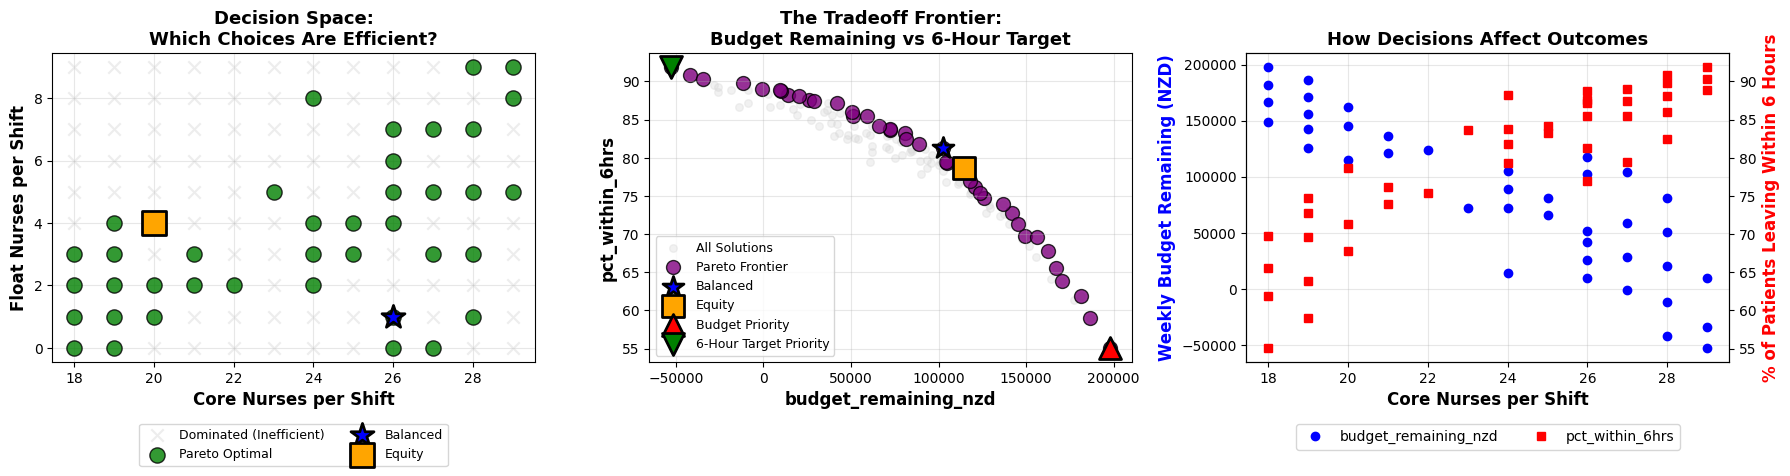


✓ Visualization saved as 'images/pareto_frontier_analysis.png'


In [12]:
import numpy as np

# Create figure with three subplots
fig = plt.figure(figsize=(18, 5))

# PANEL 1: Decision Space (show which variable combinations are efficient)
ax1 = fig.add_subplot(131)

# Plot dominated points
if len(dominated_df) > 0:
    ax1.scatter(dominated_df['core_nurses_per_shift'], dominated_df['float_nurses_per_shift'],
               s=80, c='lightgray', alpha=0.4, marker='x',
               label='Dominated (Inefficient)', zorder=1)

# Plot Pareto optimal points
ax1.scatter(pareto_df['core_nurses_per_shift'], pareto_df['float_nurses_per_shift'],
           s=120, c='green', alpha=0.8, marker='o',
           edgecolors='black', linewidth=1,
           label='Pareto Optimal', zorder=2)

# Highlight key strategies
ax1.scatter(pareto_df.loc[balanced_idx, 'core_nurses_per_shift'],
           pareto_df.loc[balanced_idx, 'float_nurses_per_shift'],
           s=300, c='blue', marker='*',
           edgecolors='black', linewidth=2,
           label='Balanced', zorder=3)

ax1.scatter(pareto_df.loc[equity_idx, 'core_nurses_per_shift'],
           pareto_df.loc[equity_idx, 'float_nurses_per_shift'],
           s=300, c='orange', marker='s',
           edgecolors='black', linewidth=2,
           label='Equity', zorder=3)

ax1.set_xlabel('Core Nurses per Shift', fontsize=12, fontweight='bold')
ax1.set_ylabel('Float Nurses per Shift', fontsize=12, fontweight='bold')
ax1.set_title('Decision Space:\nWhich Choices Are Efficient?',
             fontsize=13, fontweight='bold')
ax1.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
ax1.grid(True, alpha=0.3)

# PANEL 2: Objective Space (the Pareto frontier)
ax2 = fig.add_subplot(132)

# Plot all points
ax2.scatter(df[OBJECTIVE_1], df[OBJECTIVE_2],
           s=30, c='lightgray', alpha=0.3,
           label='All Solutions')

# Plot Pareto frontier
ax2.scatter(pareto_df[OBJECTIVE_1], pareto_df[OBJECTIVE_2],
           s=100, c='purple', alpha=0.8,
           edgecolors='black', linewidth=1,
           label='Pareto Frontier')

# Highlight strategies
strategies_to_plot = [
    (balanced_idx, 'blue', '*', 'Balanced'),
    (equity_idx, 'orange', 's', 'Equity'),
    (obj1_priority_idx, 'red', '^', 'Budget Priority'),
    (obj2_priority_idx, 'green', 'v', '6-Hour Target Priority')
]

for idx, color, marker, label in strategies_to_plot:
    ax2.scatter(pareto_df.loc[idx, OBJECTIVE_1],
               pareto_df.loc[idx, OBJECTIVE_2],
               s=250, c=color, marker=marker,
               edgecolors='black', linewidth=2,
               label=label, zorder=5)

ax2.set_xlabel(f'{OBJECTIVE_1}', fontsize=12, fontweight='bold')
ax2.set_ylabel(f'{OBJECTIVE_2}', fontsize=12, fontweight='bold')
ax2.set_title('The Tradeoff Frontier:\nBudget Remaining vs 6-Hour Target',
             fontsize=13, fontweight='bold')
ax2.legend(fontsize=9, loc='best')
ax2.grid(True, alpha=0.3)

# PANEL 3: Tradeoff Curve (both objectives vs one decision variable)
ax3 = fig.add_subplot(133)

# Sort by first decision variable for cleaner line plots
pareto_sorted = pareto_df.sort_values('core_nurses_per_shift')

ax3.plot(pareto_sorted['core_nurses_per_shift'], pareto_sorted[OBJECTIVE_1],
        'bo', markersize=6, label=OBJECTIVE_1)
ax3b = ax3.twinx()
ax3b.plot(pareto_sorted['core_nurses_per_shift'], pareto_sorted[OBJECTIVE_2],
         'rs', markersize=6, label=OBJECTIVE_2)

ax3.set_xlabel('Core Nurses per Shift', fontsize=12, fontweight='bold')
ax3.set_ylabel('Weekly Budget Remaining (NZD)', fontsize=12, fontweight='bold', color='blue')
ax3b.set_ylabel('% of Patients Leaving Within 6 Hours', fontsize=12, fontweight='bold', color='red')
ax3.set_title('How Decisions Affect Outcomes',
             fontsize=13, fontweight='bold')
handles1, labels1 = ax3.get_legend_handles_labels()
handles2, labels2 = ax3b.get_legend_handles_labels()
ax3.legend(handles1 + handles2, labels1 + labels2, fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)

ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/pareto_frontier_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Visualization saved as 'images/pareto_frontier_analysis.png'")

Panel 1 (Decision Space): Each dot represents a roster. Efficient rosters (green circles) and dominated (grey x's). There are two types of efficient roster; one with a small core size (18-22 nurses) and few floats, and another with a larger core (24-29) and more floats. Rosters with medium core sizes and few floats will generally be inefficient.

Panel 2 (Pareto frontier): The purple line shows the optimal 6hr rate that can be achieved given different budget levels. Below this line will be dominated solutions, shown in grey. Due to the flattening nature of the line, increasing one percent of the core size near the top of the graph will cost significantly more than increasing it by one percent near the bottom of the graph (60%). The highlighted solutions show how our different philosophies fit onto the curve.

Panel 3 (Roster Effectiveness): Core nurses are added to efficient rosters resulting in an increasing budget usage (blue) and increased 6hou rate (red). This shows clear diminishing returns.

Executive Summary: 2/3 possible rosters are inefficient. Solutions on the frontier provide improvements in cost and patient flow. However, as the curve has flattened it is impossible to achieve our 95% target using only rostering given the current budget.

# Summary and Insights

### Findings

There were 120 potential roster solutions for weekly ED rotations, with 40 (33.3%) of these being Pareto optimal. Rosters on the Pareto frontier show weekly budget remaining values ranging from $197,911 for (18 core, 0 float) to -$52,638 for (29 core, 9 float). The 6-hour rate ranges from 55.1% to 91.9%. There are 5 distinct strategic solutions to consider: Budget Priority (55.1%), Weighted 60/40 (72.7%), Equity (78.7%), Balanced (81.3%) and 6-Hour Target Priority (91.9%).

### Business Implications

This is a high trade-off with diminishing returns. Improving the 6-hour rate can be done cheaply at low levels of staff but gets very expensive once past ~85%. Health NZ should avoid dominated solutions like (20 core, 0 float) which is outperformed on cost and patient flow by other solutions (18 core, 1 float). Mid-core solutions (22-25 core) with little or no float also waste money. The Balanced (26 core, 1 float) and Equity (20 core, 4 float) solutions provide similar outcomes at similar cost but with different underlying principles. The Balanced solution provides a fixed solution where as the Equity solution provides a flexible solution. The efficient solutions should be chosen based on how reliable float and agency nurses are, how the ED budget is determined, and how much importance is placed on hitting the 95% target politically. No solutions within the $380,000 budget hit the 95% target (best is 88.9%). Improvements must therefore be made to the rostering alongside other measures.

### Limitations

The data is synthetic and has been created using an LLM with the values calibrated to published data. This means the patterns match real-world scenarios but does not reflect how a specific ED in Auckland would perform. In the model, it was assumed there is the same number of staff each shift throughout the week. In reality there are peaks in the patient arrival times during evenings and weekends. The 6-hour rate is dependent purely on the number of nurses. Factors such as bed availability, doctor staffing and triage mix were not considered. Constraints have not been included in my solution to ensure a minimum safe number of staff, availability of nurses, employment agreement rules and senior nurses. These will be added in Phase 2. The model could also be improved by adding decision variables for each shift and simulating the queue using the hourly arrival pattern.